# Movie Review Sentiment Analysis 

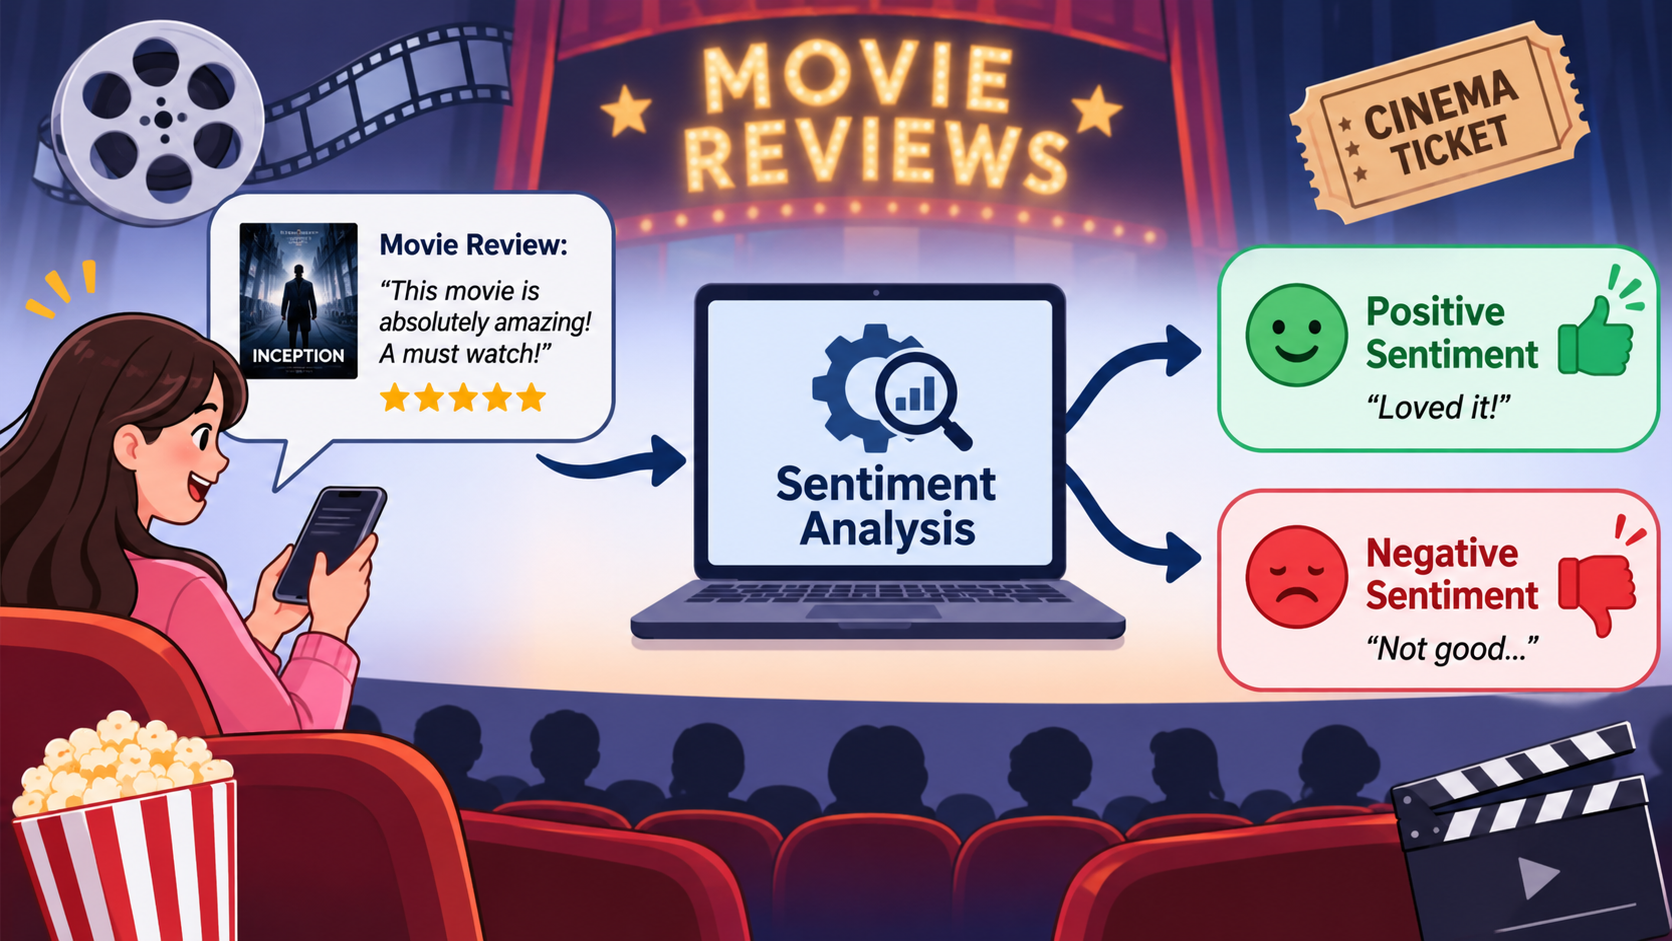

### Backstory
People often share their opinions about movies in online reviews. One review may praise the acting and story, while another may complain about the pacing or ending. When there are many reviews, reading them all individually makes it harder to get a quick sense of how viewers feel overall.

This project explores whether a computer can help sort those opinions. It learns from movie reviews that are already labeled positive or negative, then uses the language patterns it learned to predict the sentiment of a new review. TF-IDF represents the words numerically, and Multinomial Naive Bayes uses those features to make a classification.

### Problem statement
Movie reviews are written in natural language, so a computer cannot classify them directly as ordinary text. The project addresses the task of preparing review text and training a model to classify each review as positive or negative.

The model is trained on labeled reviews. For a new review, it applies the same text-cleaning steps, converts the text into TF-IDF features using the fitted vectorizer, and predicts a sentiment category with the trained Multinomial Naive Bayes classifier.

### Objective
The main objective is to build a movie-review sentiment analysis model that predicts whether a review expresses a positive or negative opinion.

The project also aims to:
- Prepare and clean movie-review text for machine learning.
- Convert text into numerical features using TF-IDF.
- Train a Multinomial Naive Bayes classifier on labeled reviews.
- Use the trained model and vectorizer to predict sentiment for new reviews.
- Evaluate how well the model classifies reviews using suitable performance measures.

### Naive Bayes

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("IMDB Dataset.csv")

In [5]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [6]:
df.shape

(50000, 2)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [8]:
 df.describe(include="str") 

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [9]:
df.columns

Index(['review', 'sentiment'], dtype='str')

In [10]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(418)

In [12]:
duplicate_percentage = (df['review'].duplicated().sum() / len(df)) * 100

print("Duplicate Percentage:", duplicate_percentage, "%")

Duplicate Percentage: 0.836 %


In [13]:
df.drop_duplicates(subset='review', inplace=True)

C:\Users\72IN\AppData\Local\Temp\ipykernel_10632\3958079673.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset='review', inplace=True)


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["sentiment"].value_counts()

sentiment
positive    24884
negative    24698
Name: count, dtype: int64

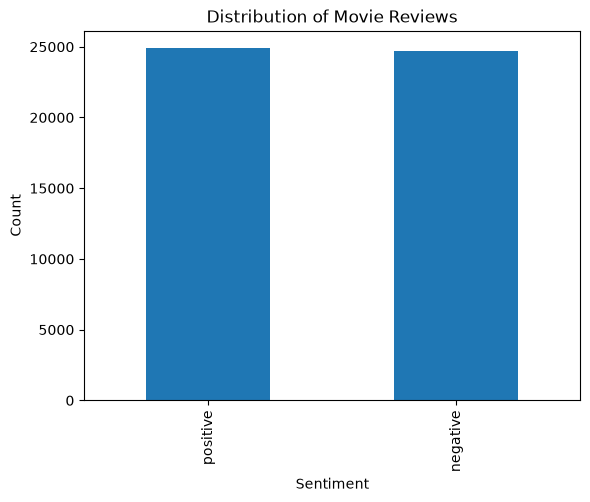

In [16]:

df['sentiment'].value_counts().plot(kind='bar')

plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.title('Distribution of Movie Reviews')
plt.show()

In [17]:
import re
import html

def clean_text(text):

    # 1. Lowercase conversion
    text = text.lower()

    # 2. Decode HTML entities
    text = html.unescape(text)

    # 3. Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # 4. Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # 5. Remove special characters and punctuation
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 6. Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [18]:
df['cleaned_review'] = df['review'].apply(clean_text)

In [19]:
df[['review', 'cleaned_review']].head()

,review,cleaned_review
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,basically there s a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",petter mattei s love in the time of money is a...


In [20]:
df.head()

,review,sentiment,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,a wonderful little production the filming tech...
2,I thought this was a wonderful way to spend ti...,positive,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,basically there s a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei s love in the time of money is a...


In [21]:
df = df.drop("review",axis = 1)
df

,sentiment,cleaned_review
0,positive,one of the other reviewers has mentioned that ...
1,positive,a wonderful little production the filming tech...
2,positive,i thought this was a wonderful way to spend ti...
3,negative,basically there s a family where a little boy ...
4,positive,petter mattei s love in the time of money is a...
...,...,...
49995,positive,i thought this movie did a down right good job...
49996,negative,bad plot bad dialogue bad acting idiotic direc...
49997,negative,i am a catholic taught in parochial elementary...
49998,negative,i m going to have to disagree with the previou...


In [22]:
df.rename(columns={'cleaned_review': 'review'}, inplace=True)

C:\Users\72IN\AppData\Local\Temp\ipykernel_10632\3986551114.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'cleaned_review': 'review'}, inplace=True)


In [23]:
df.head()

,sentiment,review
0,positive,one of the other reviewers has mentioned that ...
1,positive,a wonderful little production the filming tech...
2,positive,i thought this was a wonderful way to spend ti...
3,negative,basically there s a family where a little boy ...
4,positive,petter mattei s love in the time of money is a...


In [24]:
X = df.drop("sentiment", axis = 1)
X

,review
0,one of the other reviewers has mentioned that ...
1,a wonderful little production the filming tech...
2,i thought this was a wonderful way to spend ti...
3,basically there s a family where a little boy ...
4,petter mattei s love in the time of money is a...
...,...
49995,i thought this movie did a down right good job...
49996,bad plot bad dialogue bad acting idiotic direc...
49997,i am a catholic taught in parochial elementary...
49998,i m going to have to disagree with the previou...


In [25]:
y = df["sentiment"]
y

0        positive
1        positive
2        positive
3        negative
4        positive
           ...   
49995    positive
49996    negative
49997    negative
49998    negative
49999    negative
Name: sentiment, Length: 49582, dtype: str

In [26]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

In [27]:
print("X Train:",X_train.shape)
print("X Test:",X_test.shape)
print("Y Train:",y_train.shape)
print("Y Test:",y_test.shape)

X Train: (39665, 1)
X Test: (9917, 1)
Y Train: (39665,)
Y Test: (9917,)


In [28]:
vector = TfidfVectorizer()
vector

,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",'word'
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1

In [29]:
X_train_vector = vector.fit_transform(X_train["review"])

In [30]:
print(X_train_vector.shape)

(39665, 90635)


In [31]:
X_train_vector

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5365794 stored elements and shape (39665, 90635)>

In [32]:
model = MultinomialNB()
model.fit(X_train_vector, y_train)
model

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[19758.,19907.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.7 ,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U8](2,)","['negative','positive']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 90635)","[[1.06,1.01,0. ,...,0.16,0.16,0.16], [0.36,0.55,0.11,...,0. ,0. ,0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 90635)","[[-11.81,-11.84,-12.53,...,-12.39,-12.39,-12.39], [-12.22,-12.09,-12.42,...,-12.53,-12.53,-12.53]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,90635


In [33]:
X_test_vector = vector.transform(X_test["review"])
X_test_vector

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 1327421 stored elements and shape (9917, 90635)>

In [34]:
y_pred = model.predict(X_test_vector)

In [35]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison['Correct'] = comparison['Actual'] == comparison['Predicted']

print(comparison)

        Actual Predicted  Correct
0     negative  negative     True
1     positive  positive     True
2     positive  positive     True
3     negative  negative     True
4     negative  negative     True
...        ...       ...      ...
9912  negative  negative     True
9913  negative  negative     True
9914  positive  positive     True
9915  negative  negative     True
9916  positive  positive     True

[9917 rows x 3 columns]


In [36]:
print("Accuracy:", accuracy_score(y_test, y_pred))


Accuracy: 0.862861752546133


In [37]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[4364  576]
 [ 784 4193]]


In [38]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.85      0.88      0.87      4940
    positive       0.88      0.84      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



In [39]:
from sklearn.naive_bayes import BernoulliNB

model2 = BernoulliNB()

model2.fit(X_train_vector, y_train)

y_pred2 = model2.predict(X_test_vector)

In [40]:
print(classification_report(y_test, y_pred2))

              precision    recall  f1-score   support

    negative       0.84      0.88      0.86      4940
    positive       0.87      0.84      0.85      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



In [41]:
from sklearn.naive_bayes import ComplementNB

model3 = ComplementNB()

model3.fit(X_train_vector, y_train)

y_pred3 = model3.predict(X_test_vector)

print(classification_report(y_test, y_pred3))

              precision    recall  f1-score   support

    negative       0.85      0.88      0.87      4940
    positive       0.88      0.84      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



## Testing

In [42]:
new_reviews = [
    "This movie was absolutely amazing. I loved every moment.",
    "Very boring movie. The acting was terrible.",
    "The story was good but the ending was disappointing.",
    "Excellent performance and wonderful direction.",
    "I did not enjoy this movie at all."
]

In [43]:
new_reviews_vector = vector.transform(new_reviews)

In [44]:
new_predictions = model.predict(new_reviews_vector)

In [45]:
print(new_predictions)

['positive' 'negative' 'negative' 'positive' 'positive']


In [46]:
results = pd.DataFrame({
    "Review": new_reviews,
    "Predicted Sentiment": new_predictions
})

print(results)

                                              Review Predicted Sentiment
0  This movie was absolutely amazing. I loved eve...            positive
1        Very boring movie. The acting was terrible.            negative
2  The story was good but the ending was disappoi...            negative
3     Excellent performance and wonderful direction.            positive
4                 I did not enjoy this movie at all.            positive


## Deployment

In [47]:
import joblib

joblib.dump(model, "sentiment_model.pkl")
joblib.dump(vector, "sentiment_vectorizer.pkl")

['sentiment_vectorizer.pkl']

In [73]:
%pip install --upgrade gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [48]:
import html
import re
import gradio as gr

def predict_sentiment(review):
    if not review or not review.strip():
        return "Please enter a review."

    # Clean the text the same way as in the training notebook
    review = review.lower()
    review = html.unescape(review)
    review = re.sub(r"<.*?>", " ", review)
    review = re.sub(r"http\S+|www\S+", "", review)
    review = re.sub(r"[^a-z\s]", " ", review)
    review = re.sub(r"\s+", " ", review).strip()

    # Use the already-fitted vectorizer and trained model
    review_vector = vector.transform([review])
    prediction = model.predict(review_vector)[0]

    return str(prediction).capitalize()

demo = gr.Interface(
    fn=predict_sentiment,
    inputs=gr.Textbox(lines=5, label="Enter a movie review"),
    outputs=gr.Textbox(label="Predicted sentiment"),
    title="Movie Review Sentiment Predictor"
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
